# Baby Qwen 3/3: Knowledge Injection with LoRA

**Target Architecture**: Scaled-down Qwen2.5 (~42M parameters)  
**Curriculum Goals**:
- **Step 1: Pretraining from Scratch** (`week4/BabyQwen-1-Pretraining.ipynb`) — Causal language modeling on raw text to build a base model (*raw text → language*).
- **Step 2: Supervised Fine-Tuning** (`week5/BabyQwen-2-FineTuning.ipynb`) — ChatML template & response-only loss to teach instruction-following (*language → follows instructions*).
- **Step 3: Knowledge Injection & LoRA** (`week5/BabyQwen-3-KnowledgeInjection.ipynb`) — Parameter-efficient fine-tuning to inject new domain facts into the tuned model (*follows instructions → knows new facts*).

### Step 2 vs Step 3 at a glance

| | **Step 2: BabyQwen-2 (SFT)** | **This notebook, Step 3: BabyQwen-3 (Knowledge Injection)** |
|---|---|---|
| **Teaches** | *How* to answer: the chat format and doing what an instruction asks | *What* to answer: specific facts the model never saw |
| **Starts from** | `baby_qwen_pretrained` (only continues text) | `baby_qwen_sft` (already follows instructions) |
| **Data** | about 4,000 instruction/response pairs built from ordinary stories | 48 facts about an invented world (Willowbrook), asked in several phrasings |
| **Method** | full fine-tuning and LoRA, compared side by side | LoRA only: a small adapter on a frozen model |
| **Checked by** | does the answer contain the requested word or name? | recall of seen, rephrased and never-seen facts, plus forgetting |
| **Saves** | `baby_qwen_sft` (full model) | adapter (about 1 MB) and a merged copy |

Both steps train on prompt → response pairs with the loss on the response tokens only. Step 2 uses that recipe to teach the model **how to answer**; Step 3 reuses it, through a LoRA adapter, to teach it **what to answer**.

**Current Focus**: **Step 3** — Step 2 ended with a fundamental limit: SFT changes *behavior*, not *knowledge*. Baby Qwen can write a story about "a character named Mia", but it knows nothing about any particular Mia. Here we give it that knowledge by training a small LoRA adapter on top of the frozen `baby_qwen_sft` weights.

---

## Overview

1. Apply **LoRA** (via Hugging Face PEFT) on top of a model *you* trained, and train it with the HF `Trainer`
2. Build a fact dataset where **recall is checkable by code** (no fuzzy metrics)
3. Separate three things that are easy to confuse: recalling a **seen** question, recalling a seen fact under a **rephrased** question, and answering about a fact the model **never saw**
4. See what knowledge injection does *not* give you: honesty about what it doesn't know
5. Check for **forgetting**: does the model still write stories?
6. Save the adapter, merge it, and reload it

## The world: Willowbrook

Baby Qwen only knows TinyStories, so we invent a small story-world it has no way of knowing about: twelve children in the village of Willowbrook. Each has a **home**, a **pet**, a **favorite food** and a **best friend**, assigned at random. The facts are arbitrary on purpose. The model can only get them right by having *learned them from our data*.

| Specification | Value |
|---|---|
| Starting point | `week5/baby_qwen_sft` (from Step 2) |
| Facts | 12 characters × 4 attributes = 48 facts |
| Training data | facts about 10 characters, each asked **3 different ways** (120 examples) |
| Held out | a 4th phrasing of every seen fact, plus **all** facts about 2 characters (Sam, Amy) |
| Destination | `./baby_qwen_knowledge_adapter` & `./baby_qwen_knowledge` (merged standalone) |

---
## 1. Setup

In [1]:
import subprocess, sys
try:
    import peft
except ImportError:   # e.g. a fresh Colab runtime
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'peft'])

import os, re, math, random
import numpy as np
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM, TrainingArguments, Trainer, DataCollatorForSeq2Seq
from peft import LoraConfig, get_peft_model, TaskType, PeftModel

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
random.seed(0)
torch.manual_seed(0)
os.environ["TOKENIZERS_PARALLELISM"] = "false"
print(f"PyTorch {torch.__version__} | device: {device.upper()}")

PyTorch 2.14.1 | device: MPS


---
## 2. Load the SFT Checkpoint from BabyQwen-2

This is the model we are continuing: Baby Qwen2.5 after pretraining (BabyQwen-1) and full SFT (BabyQwen-2). Same tokenizer, same chat template, same system prompt. Only the *task* changes.

In [2]:
# Step 3 always continues from the SFT checkpoint. The optional DPO model from BabyQwen-2 (section 10)
# is saved separately in baby_qwen_dpo/ and is deliberately not used here.
SFT_DIR = "baby_qwen_sft"
assert os.path.isdir(SFT_DIR), f"{SFT_DIR} not found. Run BabyQwen-1-Pretraining.ipynb and BabyQwen-2 first."

tokenizer = AutoTokenizer.from_pretrained(SFT_DIR)
IM_END = tokenizer.convert_tokens_to_ids("<|im_end|>")
EOT = tokenizer.convert_tokens_to_ids("<|endoftext|>")
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

def load_sft():
    return AutoModelForCausalLM.from_pretrained(SFT_DIR, dtype=torch.float32).to(device)

model = load_sft()
cfg = model.config
n_params = sum(p.numel() for p in model.parameters())
print(f"Loaded {SFT_DIR}: {n_params:,} parameters")
print(f"layers={cfg.num_hidden_layers}  hidden={cfg.hidden_size}  heads={cfg.num_attention_heads} "
      f"(KV heads={cfg.num_key_value_heads})  FFN={cfg.intermediate_size}  vocab={cfg.vocab_size:,}")

Loading weights:   0%|          | 0/50 [00:00<?, ?it/s]

Loaded baby_qwen_sft: 41,844,736 parameters
layers=4  hidden=256  heads=8 (KV heads=2)  FFN=768  vocab=151,665


### Where LoRA will attach

Baby Qwen has the same block structure as the large Qwen2.5 models, just smaller: **RMSNorm → GQA self-attention → RMSNorm → SwiGLU FFN**, repeated 4 times, with tied input/output embeddings.

LoRA freezes every original weight $W_0 \in \mathbb{R}^{d \times k}$ and learns a **low-rank update**:

$$W = W_0 + \Delta W = W_0 + \frac{\alpha}{r}BA, \qquad B \in \mathbb{R}^{d \times r},\; A \in \mathbb{R}^{r \times k},\; r \ll \min(d,k)$$

$A$ starts random and $B$ starts at zero, so $\Delta W = 0$ and the adapter model begins *identical* to the SFT model. The cell below counts what each rank costs on this architecture.

In [3]:
def lora_param_count(r):
    # Each adapted Linear(in -> out) adds r*(in + out) parameters
    cfg = model.config
    d, ff = cfg.hidden_size, cfg.intermediate_size
    head_dim = d // cfg.num_attention_heads
    kv = cfg.num_key_value_heads * head_dim
    shapes = [(d, d), (d, kv), (d, kv), (d, d), (d, ff), (d, ff), (ff, d)]   # q, k, v, o, gate, up, down
    return cfg.num_hidden_layers * sum(r * (i + o) for i, o in shapes)

print(f"{'Configuration':<18} {'Trainable':>12} {'% of model':>11}")
print("-" * 44)
print(f"{'Full fine-tune':<18} {n_params:>12,} {'100%':>11}")
for r in (4, 8, 16, 32):
    p = lora_param_count(r)
    print(f"{'LoRA r=' + str(r):<18} {p:>12,} {p / n_params:>11.2%}")

Configuration         Trainable  % of model
--------------------------------------------
Full fine-tune       41,844,736        100%
LoRA r=4                 75,776       0.18%
LoRA r=8                151,552       0.36%
LoRA r=16               303,104       0.72%
LoRA r=32               606,208       1.45%


---
## 3. The Willowbrook Fact Dataset

Every fact is a `(character, attribute, value)` triple, for example `(Mia, home, barn)`. Because the value is a single known word, **we can check an answer by looking for that word**. No fuzzy overlap metric needed.

Each question is written in **four different phrasings**. We train on phrasings 0-2 and keep phrasing 3 for testing. That gives us the three test sets that matter:

| Test set | What it asks | What a pass means |
|---|---|---|
| **Seen** | the exact questions we trained on | the model memorized the training data |
| **Rephrased** | a *new wording* of a fact it was trained on | the model stored the **fact**, not just the question string |
| **Unseen** | facts about Sam and Amy, never in training | the model can *derive* the answer (it can't: these are arbitrary) |

Sam and Amy are the control. Their facts are random, so nothing the model knows can predict them. A correct answer there is luck, and the luck rate is the **chance level**.

> **Use your own facts.** To teach the model facts of your own, set `CUSTOM_FACTS` in the next cell. Each fact needs at least four phrasings of the question, the full answer sentence, and a `key` word that must appear in a correct answer, for example:
>
> ```python
> CUSTOM_FACTS = [
>     {'questions': ['Who founded Acme?', 'Who is the founder of Acme?', 'Which person started Acme?', 'Can you tell me who founded Acme?'],
>      'answer': 'Acme was founded by Dana.', 'key': 'Dana'},
>     # ... 30 or more facts work best
> ]
> ```
>
> Facts in `CUSTOM_HELD_OUT` (or the last 20% of yours) are never trained on and act as the control: expect chance-level recall on those.
>
> Keep the answer values different from one another where you can. If a held-out fact has the same answer as a trained fact, the model can get it right by luck, and the control group stops being clean.


In [4]:
NAMES = ["Mia", "Tom", "Lily", "Ben", "Sue", "Tim", "Anna", "Max", "Sam", "Kate", "Jack", "Amy"]
HELD_OUT = ["Sam", "Amy"]

VALUES = dict(
    home=["barn", "mill", "cottage", "lighthouse", "treehouse", "farm", "castle", "tent"],
    pet=["dog", "cat", "rabbit", "duck", "turtle", "parrot", "hamster", "goat"],
    food=["apples", "cookies", "pancakes", "soup", "cheese", "berries", "pie", "honey"],
)
QUESTIONS = dict(   # four phrasings per attribute; index 3 is reserved for testing
    home=["Where does {n} live?", "Where is {n}'s home?", "Which home does {n} live in?", "Can you tell me where {n} lives?"],
    pet=["What pet does {n} have?", "What is {n}'s pet?", "Which animal does {n} keep as a pet?", "Can you tell me what pet {n} has?"],
    food=["What does {n} like to eat?", "What is {n}'s favorite food?", "Which food does {n} love most?", "Can you tell me what {n} likes to eat?"],
    friend=["Who is {n}'s best friend?", "Who is {n} best friends with?", "Which friend does {n} play with most?", "Can you tell me who {n}'s best friend is?"],
)
ANSWERS = dict(home="{n} lives in the {v}.", pet="{n} has a pet {v}.",
               food="{n} loves to eat {v}.", friend="{n}'s best friend is {v}.")

rng = random.Random(7)
facts = []
for n in NAMES:
    for attr in QUESTIONS:
        v = rng.choice([x for x in NAMES if x != n]) if attr == "friend" else rng.choice(VALUES[attr])
        facts.append(dict(n=n, attr=attr, v=v))

def make_example(f, phrasing):
    return dict(q=QUESTIONS[f["attr"]][phrasing].format(n=f["n"]),
                ans=ANSWERS[f["attr"]].format(**f), key=f["v"], who=f["n"], attr=f["attr"])

seen_facts   = [f for f in facts if f["n"] not in HELD_OUT]
unseen_facts = [f for f in facts if f["n"] in HELD_OUT]

train_ex      = [make_example(f, p) for f in seen_facts for p in range(3)]
eval_seen     = [make_example(f, 0) for f in seen_facts]     # exact training questions
eval_rephrase = [make_example(f, 3) for f in seen_facts]     # new wording, same facts
eval_unseen   = [make_example(f, 0) for f in unseen_facts]   # facts never trained on

# ── USE YOUR OWN FACTS (optional) ──────────────────────────────────────────
# Each fact is {'questions': [q0, q1, q2, q3, ...], 'answer': '<full answer sentence>', 'key': '<word that must appear>'}.
# q0-q2 are different phrasings used for training; q3 is a further phrasing used to test recall.
# CUSTOM_FACTS    : facts to train on (leave as None to use Willowbrook)
# CUSTOM_HELD_OUT : facts never trained on, the control group. If None, the last 20% of CUSTOM_FACTS is held out.
# CUSTOM_OUT_OF_SCOPE : optional questions with no answer anywhere in your data
CUSTOM_FACTS = None
CUSTOM_HELD_OUT = None
CUSTOM_OUT_OF_SCOPE = None

def parse_custom(items, name):
    assert items, f'{name} is empty.'
    for k, f in enumerate(items):
        qs = f.get('questions') if isinstance(f, dict) else None
        ok = (isinstance(qs, list) and len(qs) >= 4 and all(isinstance(q, str) and q.strip() for q in qs)
              and str(f.get('answer', '')).strip() and str(f.get('key', '')).strip())
        assert ok, f"{name}[{k}] needs 'questions' (a list of at least 4 phrasings), 'answer' and 'key'."
        assert re.search(rf"\b{re.escape(f['key'])}\b", f['answer'], re.I), f"{name}[{k}]: the key '{f['key']}' must appear in the answer."
    return items

n_facts = len(facts)
OUT_OF_SCOPE = ["Where does Zed live?", "What does Mia's sister like to eat?", "Who won the 2030 FIFA World Cup?"]
if CUSTOM_FACTS is not None:
    seen_c = parse_custom(CUSTOM_FACTS, 'CUSTOM_FACTS')
    if CUSTOM_HELD_OUT is None:
        cut = max(1, int(0.8 * len(seen_c)))
        seen_c, unseen_c = seen_c[:cut], seen_c[cut:]
        assert unseen_c, 'Need at least 2 facts so some can be held out.'
    else:
        unseen_c = parse_custom(CUSTOM_HELD_OUT, 'CUSTOM_HELD_OUT')
    def custom_example(f, p):
        return dict(q=f['questions'][p], ans=f['answer'], key=f['key'], who='', attr='custom')
    train_ex      = [custom_example(f, p) for f in seen_c for p in range(3)]
    eval_seen     = [custom_example(f, 0) for f in seen_c]
    eval_rephrase = [custom_example(f, 3) for f in seen_c]
    eval_unseen   = [custom_example(f, 0) for f in unseen_c]
    n_facts = len(seen_c) + len(unseen_c)
    if CUSTOM_OUT_OF_SCOPE: OUT_OF_SCOPE = list(CUSTOM_OUT_OF_SCOPE)

if CUSTOM_FACTS is None:
    chance = float(np.mean([1 / len(VALUES[f["attr"]]) if f["attr"] != "friend" else 1 / (len(NAMES) - 1) for f in unseen_facts]))
else:
    chance = 1 / len({f["key"].lower() for f in seen_c + unseen_c})   # guessing among your distinct answer values
print(f"{n_facts} facts | train: {len(train_ex)} examples | eval: seen {len(eval_seen)}, "
      f"rephrased {len(eval_rephrase)}, unseen {len(eval_unseen)}")
print(f"Chance level on unseen facts (random guess): {chance:.1%}\n")
for e in train_ex[:3] + [eval_rephrase[0], eval_unseen[0]]:
    print(f"Q: {e['q']:<42} A: {e['ans']}")

48 facts | train: 120 examples | eval: seen 40, rephrased 40, unseen 8
Chance level on unseen facts (random guess): 11.6%

Q: Where does Mia live?                       A: Mia lives in the farm.
Q: Where is Mia's home?                       A: Mia lives in the farm.
Q: Which home does Mia live in?               A: Mia lives in the farm.
Q: Can you tell me where Mia lives?           A: Mia lives in the farm.
Q: Where does Sam live?                       A: Sam lives in the mill.


---
## 4. Chat Format and Baseline

We reuse the exact ChatML template and system prompt from BabyQwen-2. Only the content of the user and assistant turns differs: the user now asks a question and the assistant states a fact.

Before touching the weights, here is the SFT model on these questions. It has never heard of Willowbrook.

In [5]:
SYSTEM = "You are a friendly storyteller."   # identical to BabyQwen-2

def chat_prompt(user_msg):
    return (f"<|im_start|>system\n{SYSTEM}<|im_end|>\n"
            f"<|im_start|>user\n{user_msg}<|im_end|>\n"
            f"<|im_start|>assistant\n")

@torch.no_grad()
def generate(m, prompts, max_new_tokens=40, bs=32, **kw):
    # Batched greedy decoding with left padding; stops at <|im_end|> or <|endoftext|>
    m.eval()
    tokenizer.padding_side = "left"
    outs = []
    for i in range(0, len(prompts), bs):
        enc = tokenizer([chat_prompt(p) for p in prompts[i:i + bs]], return_tensors="pt", padding=True).to(m.device)
        g = m.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                       eos_token_id=[IM_END, EOT], pad_token_id=tokenizer.pad_token_id, **kw)
        outs += tokenizer.batch_decode(g[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    tokenizer.padding_side = "right"
    return [o.strip() for o in outs]

def recall_accuracy(m, examples):
    # Fraction of answers that contain the correct value word
    outs = generate(m, [e["q"] for e in examples])
    return float(np.mean([bool(re.search(rf"\b{e['key']}\b", o, re.I)) for e, o in zip(examples, outs)]))

for e in [eval_seen[0], eval_seen[1], eval_unseen[0]]:
    print(f"Q: {e['q']}\n  SFT model: {generate(model, [e['q']])[0]}\n  truth    : {e['ans']}\n")

Q: Where does Mia live?
  SFT model: Once upon a time, there was a little girl named Lily. She loved to play outside in the park. One day, she saw a big, a little girl named Lily. She wanted to play
  truth    : Mia lives in the farm.

Q: What pet does Mia have?
  SFT model: Once upon a time, there was a little girl named Lily. She loved to play outside in the park. One day, she saw a big, a little girl named Lily. She wanted to play
  truth    : Mia has a pet rabbit.

Q: Where does Sam live?
  SFT model: Once upon a time, there was a little girl named Lily. She loved to play outside in the park. One day, she saw a big, a little girl named Lily. She wanted to play
  truth    : Sam lives in the mill.



The SFT model has no idea it was asked a question: it just starts a generic story, usually about Lily. BabyQwen-2 gave it the chat template, but it is a weak 42M model and treats almost any prompt as a story opener. So the adapter has two jobs: teach the *facts*, and teach the habit of answering a question with one short sentence about them.

---
## 5. Configure and Apply LoRA

| Choice | Value | Why |
|---|---|---|
| Rank `r` | 16 | On $d=256$ a rank-16 update is a much larger fraction of the layer than rank 8 would be on a 896-wide model |
| `lora_alpha` | 32 | the usual $\alpha = 2r$ scaling |
| Target modules | all 7 linear layers | factual recall lives largely in the **FFN** layers (key-value memories), so attention-only LoRA is a weaker choice for knowledge |
| Learning rate | 1e-3 | LoRA tolerates 5-10x the full fine-tuning rate, and this model is tiny |

In [6]:
lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=16, lora_alpha=32, lora_dropout=0.05,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    bias="none",
)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

print("\nLayer 0 self-attention with LoRA injected (note lora_A / lora_B next to each frozen base_layer):")
print(model.base_model.model.model.layers[0].self_attn)

trainable params: 303,104 || all params: 42,147,840 || trainable%: 0.7191

Layer 0 self-attention with LoRA injected (note lora_A / lora_B next to each frozen base_layer):
Qwen2Attention(
  (q_proj): lora.Linear(
    (base_layer): Linear(in_features=256, out_features=256, bias=True)
    (lora_dropout): ModuleDict(
      (default): Dropout(p=0.05, inplace=False)
    )
    (lora_A): ModuleDict(
      (default): Linear(in_features=256, out_features=16, bias=False)
    )
    (lora_B): ModuleDict(
      (default): Linear(in_features=16, out_features=256, bias=False)
    )
    (lora_embedding_A): ParameterDict()
    (lora_embedding_B): ParameterDict()
    (lora_magnitude_vector): ModuleDict()
  )
  (k_proj): lora.Linear(
    (base_layer): Linear(in_features=256, out_features=64, bias=True)
    (lora_dropout): ModuleDict(
      (default): Dropout(p=0.05, inplace=False)
    )
    (lora_A): ModuleDict(
      (default): Linear(in_features=256, out_features=16, bias=False)
    )
    (lora_B): Mod

---
## 6. Tokenize with Assistant-Only Loss

Same idea as BabyQwen-2: labels equal the input ids, except everything up to and including `<|im_start|>assistant\n` is masked with `-100`. The model is trained to *produce the answer*, not to predict the question. The final `<|im_end|>` stays in the loss so it learns to stop.

In [7]:
def encode_example(e):
    prompt_ids = tokenizer.encode(chat_prompt(e["q"]))
    answer_ids = tokenizer.encode(e["ans"]) + [IM_END]
    ids = prompt_ids + answer_ids
    return dict(input_ids=ids, attention_mask=[1] * len(ids), labels=[-100] * len(prompt_ids) + answer_ids)

train_ds    = [encode_example(e) for e in train_ex]
rephrase_ds = [encode_example(e) for e in eval_rephrase]
unseen_ds   = [encode_example(e) for e in eval_unseen]

lengths = [len(x["input_ids"]) for x in train_ds]
trained = [sum(l != -100 for l in x["labels"]) for x in train_ds]
print(f"Tokens per example (mean): {np.mean(lengths):.0f} | with loss (answer only): {np.mean(trained):.0f} "
      f"({np.mean(trained) / np.mean(lengths):.0%})")

Tokens per example (mean): 34 | with loss (answer only): 8 (22%)


---
## 7. Training

Hugging Face `Trainer` with settings suited to a tiny model and a tiny dataset. We evaluate the **rephrased** questions every 5 epochs, so the validation curve measures whether the *facts* are being stored, not just the training strings.

| Hyperparameter | Value | Rationale |
|---|---|---|
| Epochs | 30 (more for a small custom dataset) | 120 examples is very little data, and memorizing facts takes many passes. The code raises the epoch count so there are at least ~450 steps |
| Batch size | 8 | 15 steps per epoch |
| Learning rate | 1e-3 | see section 5 |
| Scheduler | cosine, 5% warmup | smooth decay |
| Weight decay | 0 | we *want* to memorize |

In [8]:
# Memorizing facts needs enough optimizer steps (about 450). With a small custom dataset that means more epochs.
EPOCHS = max(30, math.ceil(450 / math.ceil(len(train_ds) / 8)))   # 30 for the Willowbrook data

OUTPUT_DIR = "./knowledge_lora_runs"
training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    learning_rate=1e-3,
    lr_scheduler_type="cosine",
    warmup_steps=0.05,
    weight_decay=0.0,
    max_grad_norm=1.0,
    logging_steps=15,
    eval_strategy="steps", eval_steps=75,
    save_strategy="no",
    report_to="none",
    disable_tqdm=True,
    seed=0,
)
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=rephrase_ds,
    processing_class=tokenizer,
    data_collator=DataCollatorForSeq2Seq(tokenizer, model=model, label_pad_token_id=-100),
)
train_result = trainer.train()
print(f"\nFinal train loss: {train_result.metrics['train_loss']:.4f} | runtime: {train_result.metrics['train_runtime']:.0f}s")

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151643, 'pad_token_id': 151643}.


/opt/homebrew/anaconda3/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'loss': '4.652', 'grad_norm': '3.752', 'learning_rate': '0.0006087', 'epoch': '1'}


{'loss': '2.777', 'grad_norm': '1.704', 'learning_rate': '0.0009995', 'epoch': '2'}


{'loss': '2.002', 'grad_norm': '1.226', 'learning_rate': '0.000994', 'epoch': '3'}


{'loss': '1.596', 'grad_norm': '0.8329', 'learning_rate': '0.0009826', 'epoch': '4'}


... (22 outputs left out)

{'loss': '0.5013', 'grad_norm': '0.2475', 'learning_rate': '2.836e-05', 'epoch': '27'}


{'loss': '0.4984', 'grad_norm': '0.1918', 'learning_rate': '1.295e-05', 'epoch': '28'}


{'loss': '0.4991', 'grad_norm': '0.2477', 'learning_rate': '3.46e-06', 'epoch': '29'}


{'loss': '0.5002', 'grad_norm': '0.2024', 'learning_rate': '1.353e-08', 'epoch': '30'}
{'eval_loss': '0.5738', 'eval_runtime': '0.0584', 'eval_samples_per_second': '684.4', 'eval_steps_per_second': '51.33', 'epoch': '30'}
{'train_runtime': '27.5', 'train_samples_per_second': '130.9', 'train_steps_per_second': '16.37', 'train_loss': '0.9391', 'epoch': '30'}

Final train loss: 0.9391 | runtime: 27s


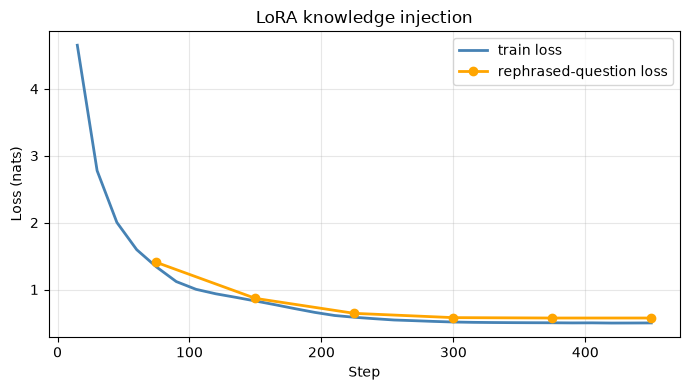

In [9]:
logs = trainer.state.log_history
tr = [x for x in logs if "loss" in x and "eval_loss" not in x]
ev = [x for x in logs if "eval_loss" in x]

plt.figure(figsize=(7, 4))
plt.plot([x["step"] for x in tr], [x["loss"] for x in tr], color="steelblue", lw=2, label="train loss")
plt.plot([x["step"] for x in ev], [x["eval_loss"] for x in ev], color="orange", marker="o", lw=2, label="rephrased-question loss")
plt.xlabel("Step"); plt.ylabel("Loss (nats)"); plt.title("LoRA knowledge injection"); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.show()

---
## 8. Did the Model Learn the Facts?

Each test compares the **SFT model** (adapter switched off, which is exactly the BabyQwen-2 model) with the **tuned model** (adapter on), on the same weights. We score every answer by whether it contains the correct value.

In [10]:
def compare(e):
    with model.disable_adapter():
        base = generate(model, [e["q"]])[0]
    tuned = generate(model, [e["q"]])[0]
    print(f"Q: {e['q']}\n  SFT   : {base}\n  TUNED : {tuned}\n  TRUTH : {e['ans']}\n")

print("=== Rephrased questions (new wording, fact was in training) ===")
for e in eval_rephrase[:3]: compare(e)
print("=== Unseen facts (Sam and Amy, never in training) ===")
for e in eval_unseen[:3]: compare(e)

=== Rephrased questions (new wording, fact was in training) ===


Q: Can you tell me where Mia lives?
  SFT   : Once upon a time, there was a little girl named Lily. She loved to play outside in the park with her friends. One day, she saw a big, a little girl named Lily. She
  TUNED : Mia lives in the farm.
  TRUTH : Mia lives in the farm.

Q: Can you tell me what pet Mia has?
  SFT   : Once upon a time, there was a little girl named Lily. She loved to play outside in the park with her friends. One day, she saw a big, a little girl named Lily. She
  TUNED : Mia's best friend is Amy.
  TRUTH : Mia has a pet rabbit.



Q: Can you tell me what Mia likes to eat?
  SFT   : Once upon a time, there was a little girl named Lily. She loved to play outside in the park with her friends. One day, she saw a big, a little girl named Lily. She
  TUNED : Mia loves to eat pie.
  TRUTH : Mia loves to eat pie.

=== Unseen facts (Sam and Amy, never in training) ===
Q: Where does Sam live?
  SFT   : Once upon a time, there was a little girl named Lily. She loved to play outside in the park. One day, she saw a big, a little girl named Lily. She wanted to play
  TUNED : Tom lives in the barn.
  TRUTH : Sam lives in the mill.



Q: What pet does Sam have?
  SFT   : Once upon a time, there was a little girl named Lily. She loved to play outside in the park. One day, she saw a big, a little girl named Lily. She wanted to play
  TUNED : Tom has a pet cat.
  TRUTH : Sam has a pet turtle.

Q: What does Sam like to eat?
  SFT   : Once upon a time, there was a little girl named Lily. She loved to play outside in the park. One day, she saw a big, a little girl named Lily. She wanted to play
  TUNED : Tom loves to eat cookies.
  TRUTH : Sam loves to eat pancakes.



Test set                 n  SFT model  LoRA tuned
-------------------------------------------------
Seen questions          40         2%        100%
Rephrased questions     40         2%         92%
Unseen facts             8         0%         12%
(chance level)                    12%


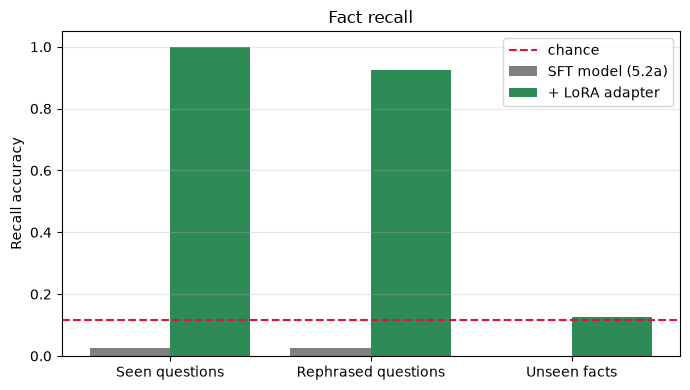

In [11]:
sets = [("Seen questions", eval_seen), ("Rephrased questions", eval_rephrase), ("Unseen facts", eval_unseen)]
rows = []
for name, exs in sets:
    with model.disable_adapter():
        b = recall_accuracy(model, exs)
    rows.append((name, len(exs), b, recall_accuracy(model, exs)))

print(f"{'Test set':<22} {'n':>3} {'SFT model':>10} {'LoRA tuned':>11}")
print("-" * 49)
for name, n, b, t in rows:
    print(f"{name:<22} {n:>3} {b:>10.0%} {t:>11.0%}")
print(f"{'(chance level)':<22} {'':>3} {chance:>10.0%}")

x = np.arange(len(rows))
plt.figure(figsize=(7, 4))
plt.bar(x - 0.2, [r[2] for r in rows], 0.4, label="SFT model (BabyQwen-2)", color="gray")
plt.bar(x + 0.2, [r[3] for r in rows], 0.4, label="+ LoRA adapter", color="seagreen")
plt.axhline(chance, color="crimson", ls="--", label="chance")
plt.xticks(x, [r[0] for r in rows]); plt.ylim(0, 1.05); plt.ylabel("Recall accuracy")
plt.title("Fact recall"); plt.legend(); plt.grid(alpha=0.3, axis="y"); plt.tight_layout(); plt.show()

## 9. Reading the Results

- **Seen and rephrased questions jump from about 0% to near-perfect.** The SFT model scores near zero because it writes a story instead of answering at all.
  The rephrased test is the important one: those exact words were never trained on, so the model stored the *fact* `(Mia, home, barn)` and can retrieve it through different wording.
- **Unseen facts stay at chance.** Sam's and Amy's facts are arbitrary, so no amount of training on the other ten characters can reveal them. LoRA is not a way to make a model *know more than you told it*.
- Note *how* it fails on the unseen facts: the tuned model answers fluently and confidently, usually about a *different* character it does know. It has learned to produce a confident fact-shaped sentence, not to know when it lacks the fact.

### Out-of-scope questions

A trustworthy assistant would say it doesn't know. Here are questions with no answer anywhere in the data: a character who doesn't exist, an attribute we never trained, and a question from the real world.

In [12]:
for q in OUT_OF_SCOPE:
    compare(dict(q=q, ans="(no correct answer exists)"))

Q: Where does Zed live?
  SFT   : Once upon a time, there was a little girl named Lily. She loved to play outside in the park. One day, she saw a big, a little girl named Lily. She wanted to play
  TUNED : Mia lives in the mill.
  TRUTH : (no correct answer exists)



Q: What does Mia's sister like to eat?
  SFT   : Once upon a time, there was a little girl named Lily. She loved to play outside in the park. One day, she saw a big, a little girl named Lily. She wanted to play
  TUNED : Mia loves to eat pie.
  TRUTH : (no correct answer exists)



Q: Who won the 2030 FIFA World Cup?
  SFT   : Once upon a time, there was a little girl named Lily. She loved to play outside in the park. One day, she saw a big, a little girl named Lily. She wanted to play
  TUNED : Mia loves to eat soup.
  TRUTH : (no correct answer exists)



The model answers anyway. It was never shown an example of refusing, so "I don't know" is not part of what it learned. Ways to fix this:

- add **refusal examples** ("I don't know about that.") to the training data
- ground answers in retrieved documents (**RAG**) instead of weights
- apply **preference optimization** against hallucinated answers (see notebook 5.2)

---
## 10. Held-Out Loss

Loss on the **answer tokens** gives a smoother signal than accuracy. We compute it with the adapter off and on, for rephrased questions (seen facts) and for unseen facts.

$$\text{PPL} = \exp\left(\frac{1}{N}\sum_{i=1}^{N} -\log p(x_i \mid x_{<i})\right)$$

In [13]:
def answer_ppl(ds):
    return math.exp(trainer.evaluate(eval_dataset=ds)["eval_loss"])

with model.disable_adapter():
    base_re, base_un = answer_ppl(rephrase_ds), answer_ppl(unseen_ds)
tuned_re, tuned_un = answer_ppl(rephrase_ds), answer_ppl(unseen_ds)

print(f"{'Answer perplexity':<26} {'SFT model':>10} {'LoRA tuned':>11}")
print("-" * 49)
print(f"{'rephrased (seen facts)':<26} {base_re:>10.2f} {tuned_re:>11.2f}")
print(f"{'unseen facts':<26} {base_un:>10.2f} {tuned_un:>11.2f}")

{'eval_loss': '5.593', 'eval_runtime': '0.0654', 'eval_samples_per_second': '612', 'eval_steps_per_second': '45.9', 'epoch': '30'}
{'eval_loss': '6.06', 'eval_runtime': '0.0127', 'eval_samples_per_second': '628.1', 'eval_steps_per_second': '78.51', 'epoch': '30'}
{'eval_loss': '0.5738', 'eval_runtime': '0.0566', 'eval_samples_per_second': '707.1', 'eval_steps_per_second': '53.03', 'epoch': '30'}
{'eval_loss': '2.019', 'eval_runtime': '0.0145', 'eval_samples_per_second': '550.7', 'eval_steps_per_second': '68.84', 'epoch': '30'}
Answer perplexity           SFT model  LoRA tuned
-------------------------------------------------
rephrased (seen facts)         268.43        1.77
unseen facts                   428.26        7.53


/opt/homebrew/anaconda3/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Perplexity collapses on the facts it was taught. It also drops sharply on the unseen facts, but that is the *format* ("Name lives in the ...") becoming easy to predict. It stays several times higher than for the seen facts, because the value word itself is still unknown.

---
## 11. Did It Forget How to Write Stories?

LoRA leaves the original weights untouched, but the *combined* model can still change behavior. BabyQwen-2's task was writing a story about a named character. We give the same 12 names to the model with the adapter off and on, and measure how often it still produces a story (longer than 150 characters) instead of a one-line fact.

In [14]:
story_prompts = [f"Write a short story about a character named {n}." for n in NAMES]

def story_rate(m):
    outs = generate(m, story_prompts, max_new_tokens=160, repetition_penalty=1.1)
    return float(np.mean([len(o) > 150 for o in outs])), outs

with model.disable_adapter():
    r_off, outs_off = story_rate(model)
r_on, outs_on = story_rate(model)
print(f"Story prompts answered with a story | adapter off: {r_off:.0%} | adapter on: {r_on:.0%}\n")
print("PROMPT     :", story_prompts[0])
print("ADAPTER OFF:", outs_off[0][:200])
print("ADAPTER ON :", outs_on[0][:200])

Story prompts answered with a story | adapter off: 100% | adapter on: 0%

PROMPT     : Write a short story about a character named Mia.
ADAPTER OFF: Once upon a time, there was a little girl named Lily. She loved to play outside in the park with her friends. One day, she saw a big, a little girl named Lily. She wanted to play with it, but she didn
ADAPTER ON : Mia loves to eat pie.


With the adapter on, the model answers story prompts with a one-line fact. This is **interference**: every training example was a short factual answer, so the adapter taught "answer in one sentence" as a general habit, not just for Willowbrook questions. Two things follow:

- **It is reversible.** The adapter is a separate file. Switch it off and the BabyQwen-2 model returns exactly, which is a real advantage of LoRA over full fine-tuning, where the new skill overwrites the old weights.
- **It is preventable.** Mix a few story examples into the training set (*replay data*) so the adapter learns that stories and questions are different tasks.

---
## 12. Save, Merge, Reload

The adapter is a tiny file next to the 42M-parameter model it modifies. We save it, then reload it on a **fresh** copy of `baby_qwen_sft`, and verify the reloaded model answers identically. Finally we **merge** the update into the weights, $W = W_0 + \frac{\alpha}{r}BA$, to get a standalone model with no PEFT dependency.

In [15]:
ADAPTER_DIR = "baby_qwen_knowledge_adapter"
MERGED_DIR = "baby_qwen_knowledge"
model.save_pretrained(ADAPTER_DIR)

adapter_mb = os.path.getsize(os.path.join(ADAPTER_DIR, "adapter_model.safetensors")) / 1e6
sft_mb = os.path.getsize(os.path.join(SFT_DIR, "model.safetensors")) / 1e6
print(f"Adapter: {adapter_mb:.1f} MB   vs   full SFT model: {sft_mb:.0f} MB   ({adapter_mb / sft_mb:.1%})")

probe = eval_rephrase + eval_unseen
live_answers = generate(model, [e["q"] for e in probe])

# 1) Reload the adapter onto a fresh base
reloaded = PeftModel.from_pretrained(load_sft(), ADAPTER_DIR)
same_adapter = generate(reloaded, [e["q"] for e in probe]) == live_answers
print(f"Reloaded adapter answers identical to in-memory model: {same_adapter}")

# 2) Merge into the weights and save a standalone model
merged = reloaded.merge_and_unload()
merged.save_pretrained(MERGED_DIR)
tokenizer.save_pretrained(MERGED_DIR)
same_merged = generate(merged, [e["q"] for e in probe]) == live_answers
print(f"Merged model (no adapter modules) answers identical:   {same_merged}")
print(f"Saved merged model to {MERGED_DIR}/")
del reloaded, merged

Adapter: 1.2 MB   vs   full SFT model: 167 MB   (0.7%)


Loading weights:   0%|          | 0/50 [00:00<?, ?it/s]

Reloaded adapter answers identical to in-memory model: True


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Merged model (no adapter modules) answers identical:   True
Saved merged model to baby_qwen_knowledge/


---
## 13. LoRA Hyperparameter Guide

**Rank `r`.** Capacity of the update. Too low and it can't hold the facts; too high and it memorizes noise and costs more. The parameter table in section 2 shows the cost on this model. Rule of thumb: the *smaller* the model, the *larger* the useful rank relative to the width.

**Alpha `lora_alpha`.** Scales the update by $\alpha / r$, so it acts like an extra learning-rate knob. The common default is $\alpha = 2r$. Higher alpha means a larger, more plastic update and more forgetting.

**Target modules.**

| Target modules | Quality |
|---|---|
| `q_proj, v_proj` only | decent for *style*, weak for new facts |
| `q, k, v, o` (attention) | good for behavior shifts |
| all 7 (attention + FFN) | best for **knowledge injection**: FFN layers act as key-value memories |

**Dropout.** 0.05 is a light regularizer. On very small datasets like this one, 0.1-0.2 can reduce overfitting, but here we *want* the model to memorize.

**Epochs and learning rate.** Facts need many passes. Watch the *rephrased-question* loss, not the training loss: training loss always falls, but the rephrased loss tells you whether the model stored the fact or just the string.

---
## Summary & Key Takeaways

| Step | What we did |
|---|---|
| Starting point | `baby_qwen_sft` from BabyQwen-2 (itself continued from BabyQwen-1's `baby_qwen_pretrained`) |
| Data | 48 Willowbrook facts; 120 training questions, 4th phrasing and 2 whole characters held out |
| LoRA | r=16, alpha=32, all 7 linear layers, about 0.7% of parameters |
| Result | seen and rephrased recall near-perfect; unseen facts at chance |
| Failure mode | confident wrong answers for unseen facts and out-of-scope questions |
| Interference | with the adapter on, story prompts get a one-line fact; switching it off restores the BabyQwen-2 model |
| Artifacts | `baby_qwen_knowledge_adapter/` (adapter) and `baby_qwen_knowledge/` (merged model) |

1. **LoRA injects knowledge you give it, nothing more.** Recall of trained facts goes from chance to near-perfect, even under rephrasing. Facts you did not provide stay at chance.
2. **Test the right thing.** Seen-question accuracy only shows memorization. The rephrased set shows the fact was stored, and the unseen set is the control that sets chance.
3. **Fluency is not truthfulness.** The tuned model states wrong facts as confidently as right ones and has no way to say "I don't know". Refusal data, RAG, and preference tuning address this.
4. **Adapters are reversible but not free.** Training only on Q&A made the model answer everything in one line. Switching the adapter off restores the previous model exactly, and replay data prevents the drift. Merging produces a standalone checkpoint.
5. **The model's whole history is now visible:** pretraining (BabyQwen-1) gave it language, SFT (BabyQwen-2) gave it the chat format, and LoRA (BabyQwen-3) gave it facts. Each stage built on the previous checkpoint.